<div style="border:4px solid #b00020; background:#ffe5e8; color:#600010; padding:14px 18px; border-radius:6px;">
<h2 style="margin:0 0 8px 0; color:#b00020;">&#9888; WARNING: THE SAMPLE TIME HAS CHANGED</h2>
<p style="margin:4px 0;"><b>The phonon sample period is 0.8 &micro;s (1.25 MHz), not 1.6 &micro;s (625 kHz).</b> A 4096-sample trace is 3.2768 ms. Until 2026-10-22 this notebook used 1.6 &micro;s, which was wrong.</p>
<p style="margin:4px 0;">What this means: times and energies are <b>half</b> of what older versions showed, frequencies are <b>doubled</b>. The time windows in this notebook (in &micro;s or ms) were halved so that they still cover the same samples, so the selection of events and every number counted in samples or counts is unchanged; the absorbed energies are half of what the earlier version printed.</p>
<p style="margin:4px 0;">This notebook was re-run with the new value (the library default, <code>PulseConfig</code> without <code>sample_period_s</code>). See <i>The sample period</i> in <code>python/README.md</code>.</p>
</div>

# Small triggers over the detector channel layout, series 07221203_2025, dump 1

The same small real triggers as in `small-physics-triggers-07221203_2025.ipynb`, drawn **on the detector layout** instead of a grid of tiles. Nothing is dropped from the tiled figures: every working channel keeps its whole trace (baseline subtracted, grey fit bands, dashed trigger line), all channels of an event share one vertical scale, and each panel carries the channel name, board and rise height.

What the layout adds:

1. **A map in the middle, traces around it.** The two faces are drawn as in the Note 9 channel figure; each working channel's trace is a full-size panel next to its region, joined to it by a leader line. (The thin rings A and B cannot hold a trace, which is why the traces sit in the margin.)
2. **Regions coloured by rise height**, on one colour scale per event, so the pattern of heights across the faces is visible at a glance. The Side 1 / Side 2 colour moves to the frames of the trace panels.
3. **Dead channels stay hatched, with no trace**, as in the Note 9 figure.
4. **Both faces together**, Side 1 on the left and Side 2 on the right (flipped as on the wiki), with the x and y arrows.
5. **A contact sheet** of many events as small maps with the heights printed.
6. **A height-weighted centre** (white star): the mean of the region centres weighted by the rise heights. It is a rough guide to where on the face the event is, not a position reconstruction; the ring channels A and B count as sitting at the centre.

The baseline is a quadratic fitted to the pretrigger samples and to the late tail of the trace, leaving the pulse out (compared with a straight line in section 6 of the first notebook). The helper code is in `small_triggers.py` (the drift-robust rise height and the baseline) and `detector_layout.py` (the drawing), next to this notebook.

In [1]:
import sys
from pathlib import Path
# Find the project's python folder from wherever this notebook is, however deep.
_here = Path.cwd().resolve()
REPO = next((p for p in [_here, *_here.parents] if (p / "python" / "pulse_io.py").exists()), None)
assert REPO, "Start Jupyter from inside the NSDF-Data folder."
sys.path.insert(0, str(REPO / "python"))
sys.path.insert(0, str(Path.cwd().resolve()))      # this notebook's folder, for the two helper modules

import warnings
import numpy as np
import matplotlib.pyplot as plt
from nsdf_dark_matter.idx import load_all_data

import pulse_io as pio
import pulse_cuts as pc
import pulse_channels as pch
from pulse_config import PulseConfig

import check_environment
check_environment.check()

import small_triggers as st
import detector_layout as dl

warnings.filterwarnings("once")
FIGDIR = Path("..") / "figures"      # the figures folder of the R76 notebooks
FIGDIR.mkdir(exist_ok=True)

Environment OK: Python 3.12.15, and the 8 packages in requirements.txt match.


C:\Users\villanoa\Research\NSDF-Data-pn\data_analysis\R76\notebooks\pulse-normalization\detector_layout.py:27: UserWarning: all_channels is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  CHANNELS = {(c.side, c.letter): c for c in pch.all_channels()}


## 1. Load the dump, the rise heights and the selection

The same steps as in the first notebook: the real triggers (label `Unknown`, the labels are swapped), the drift-robust rise height of every event in every working channel, the quiet-pretrigger cut (no pulse, step or strong curvature in the pretrigger window, section 3b of the first notebook) and the provisional small-pulse range `AMP_LOW` to `AMP_HIGH`.

In [2]:
DUMP = "07221203_2025_F0001"          # series 07221203_2025, dump 1
config_500 = PulseConfig(pretrigger_samples=500, glitch_samples=10)
cdms = load_all_data(str(Path.home() / "idx" / DUMP))
det_ids = {det: pio.filter_by_detector(cdms.get_detector_ids(), det) for det in range(3)}
KEYS = [(det, ch) for det in range(3) for ch in range(4)]

trigger_types = pio.trigger_types(cdms, det_ids[0])
real = pc.real_triggers(trigger_types)       # label 'Unknown': the pulse triggers (the labels are swapped)
rand = pc.randoms(trigger_types)
event_numbers = np.array([int(pio.event_id(i)) for i in det_ids[0]])

amp, pre_rms, dead = {}, {}, []
for key in KEYS:
    _, p = pio.load_channel_batch(cdms, det_ids[key[0]], key[1])
    if np.all(p.std(axis=1) == 0):
        dead.append(key)
        continue
    amp[key] = st.rise_height(p, config_500)
    pre_rms[key] = st.pretrigger_residual_rms(p, config_500)
working = list(amp)
side_letter = lambda key: (pch.channel_info(*key).side, pch.channel_info(*key).letter)
A = np.array([amp[k] for k in working])
amp_max = A.max(axis=0)
max_channel = [working[i] for i in A.argmax(axis=0)]

AMP_LOW, AMP_HIGH = 15.0, 200.0           # counts: provisional range for 'small pulses'
pre_ratio, quiet_pre = st.quiet_pretrigger(pre_rms, rand)      # no pulse, step or strong curvature in the pretrigger window
small = real & quiet_pre & (amp_max >= AMP_LOW) & (amp_max < AMP_HIGH)
print(f"{len(working)} working channels; {small.sum()} of {real.sum()} real triggers have a quiet pretrigger and a largest rise height between {AMP_LOW:.0f} and {AMP_HIGH:.0f} counts")

def heights_of(i):
    """(side, letter) -> rise height of event i, for the working channels."""
    return {side_letter(k): float(amp[k][i]) for k in working}

def spread(n):
    """n selected events spread evenly in height through the selection, smallest first."""
    order = np.flatnonzero(small)[np.argsort(amp_max[small])]
    return order[np.linspace(0, len(order) - 1, n + 2).astype(int)[1:-1]]

C:\Users\villanoa\AppData\Local\Temp\ipykernel_24348\1976294917.py:8: UserWarning: real_triggers is marked under_development: the other half of the randoms assumption: events recorded as 'Unknown' are taken to be real (pulse-triggered) events. Not confirmed; see `randoms`
  real = pc.real_triggers(trigger_types)       # label 'Unknown': the pulse triggers (the labels are swapped)
C:\Users\villanoa\AppData\Local\Temp\ipykernel_24348\1976294917.py:9: UserWarning: randoms is marked under_development: assumes the dump's trigger_type labels are swapped relative to their names: events recorded as 'Physics' are taken to be randoms (fixed-count random triggers) and 'Unknown' to be real triggers. That mapping is a working assumption from 07221203_2025_F0001 (see Note 2a), not confirmed against the DAQ configuration or the nsdf library
  rand = pc.randoms(trigger_types)


7 working channels; 48 of 509 real triggers have a quiet pretrigger and a largest rise height between 15 and 200 counts


## 2. One event over the detector layout

For each chosen event: the two faces with the regions coloured by rise height, and the whole trace of each working channel around them, on one vertical scale (set by the largest pulse of the event, in the window from 200 us before to 750 us after the trigger). The scale is shared by all panels of the event, so the channels can be compared by eye; a slow drift far from the pulse can run off the edge. To look at particular events put their numbers in `EVENTS`.

C:\Users\villanoa\AppData\Local\Temp\ipykernel_24348\1976294917.py:21: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  side_letter = lambda key: (pch.channel_info(*key).side, pch.channel_info(*key).letter)
C:\Users\villanoa\AppData\Local\Temp\ipykernel_24348\492353456.py:23: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  subtitle=f": largest rise height {amp_max[i]:.0f} counts in {pch.channel_name(*max_channel[i])}")
C:\Users\villanoa\Research\NSDF-Data-pn\python\pulse_channels.py:83: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferre

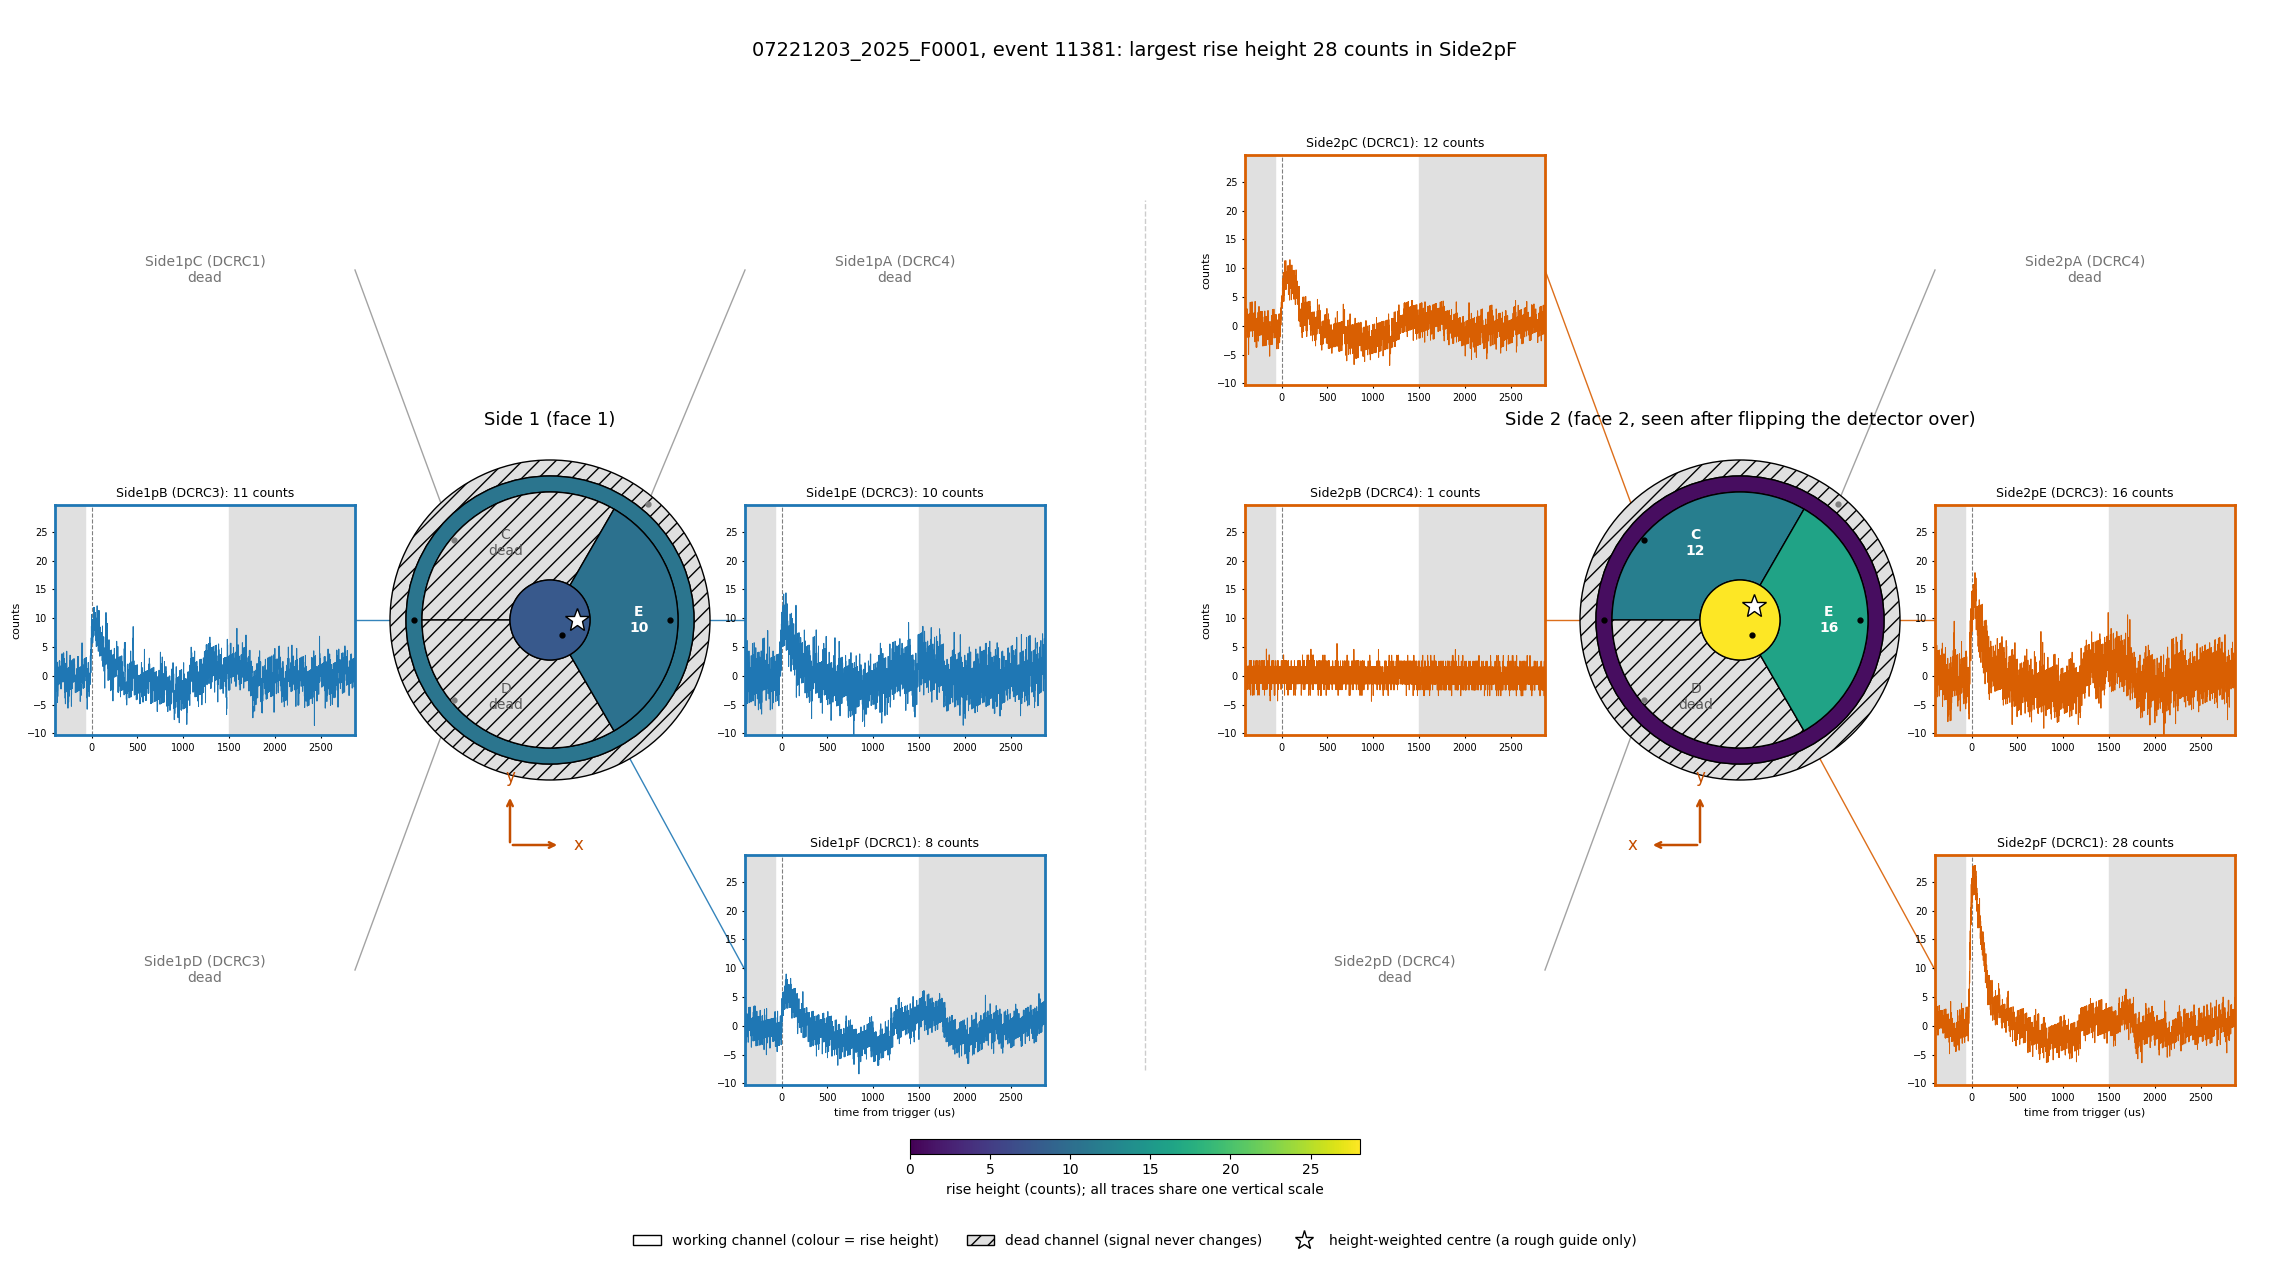

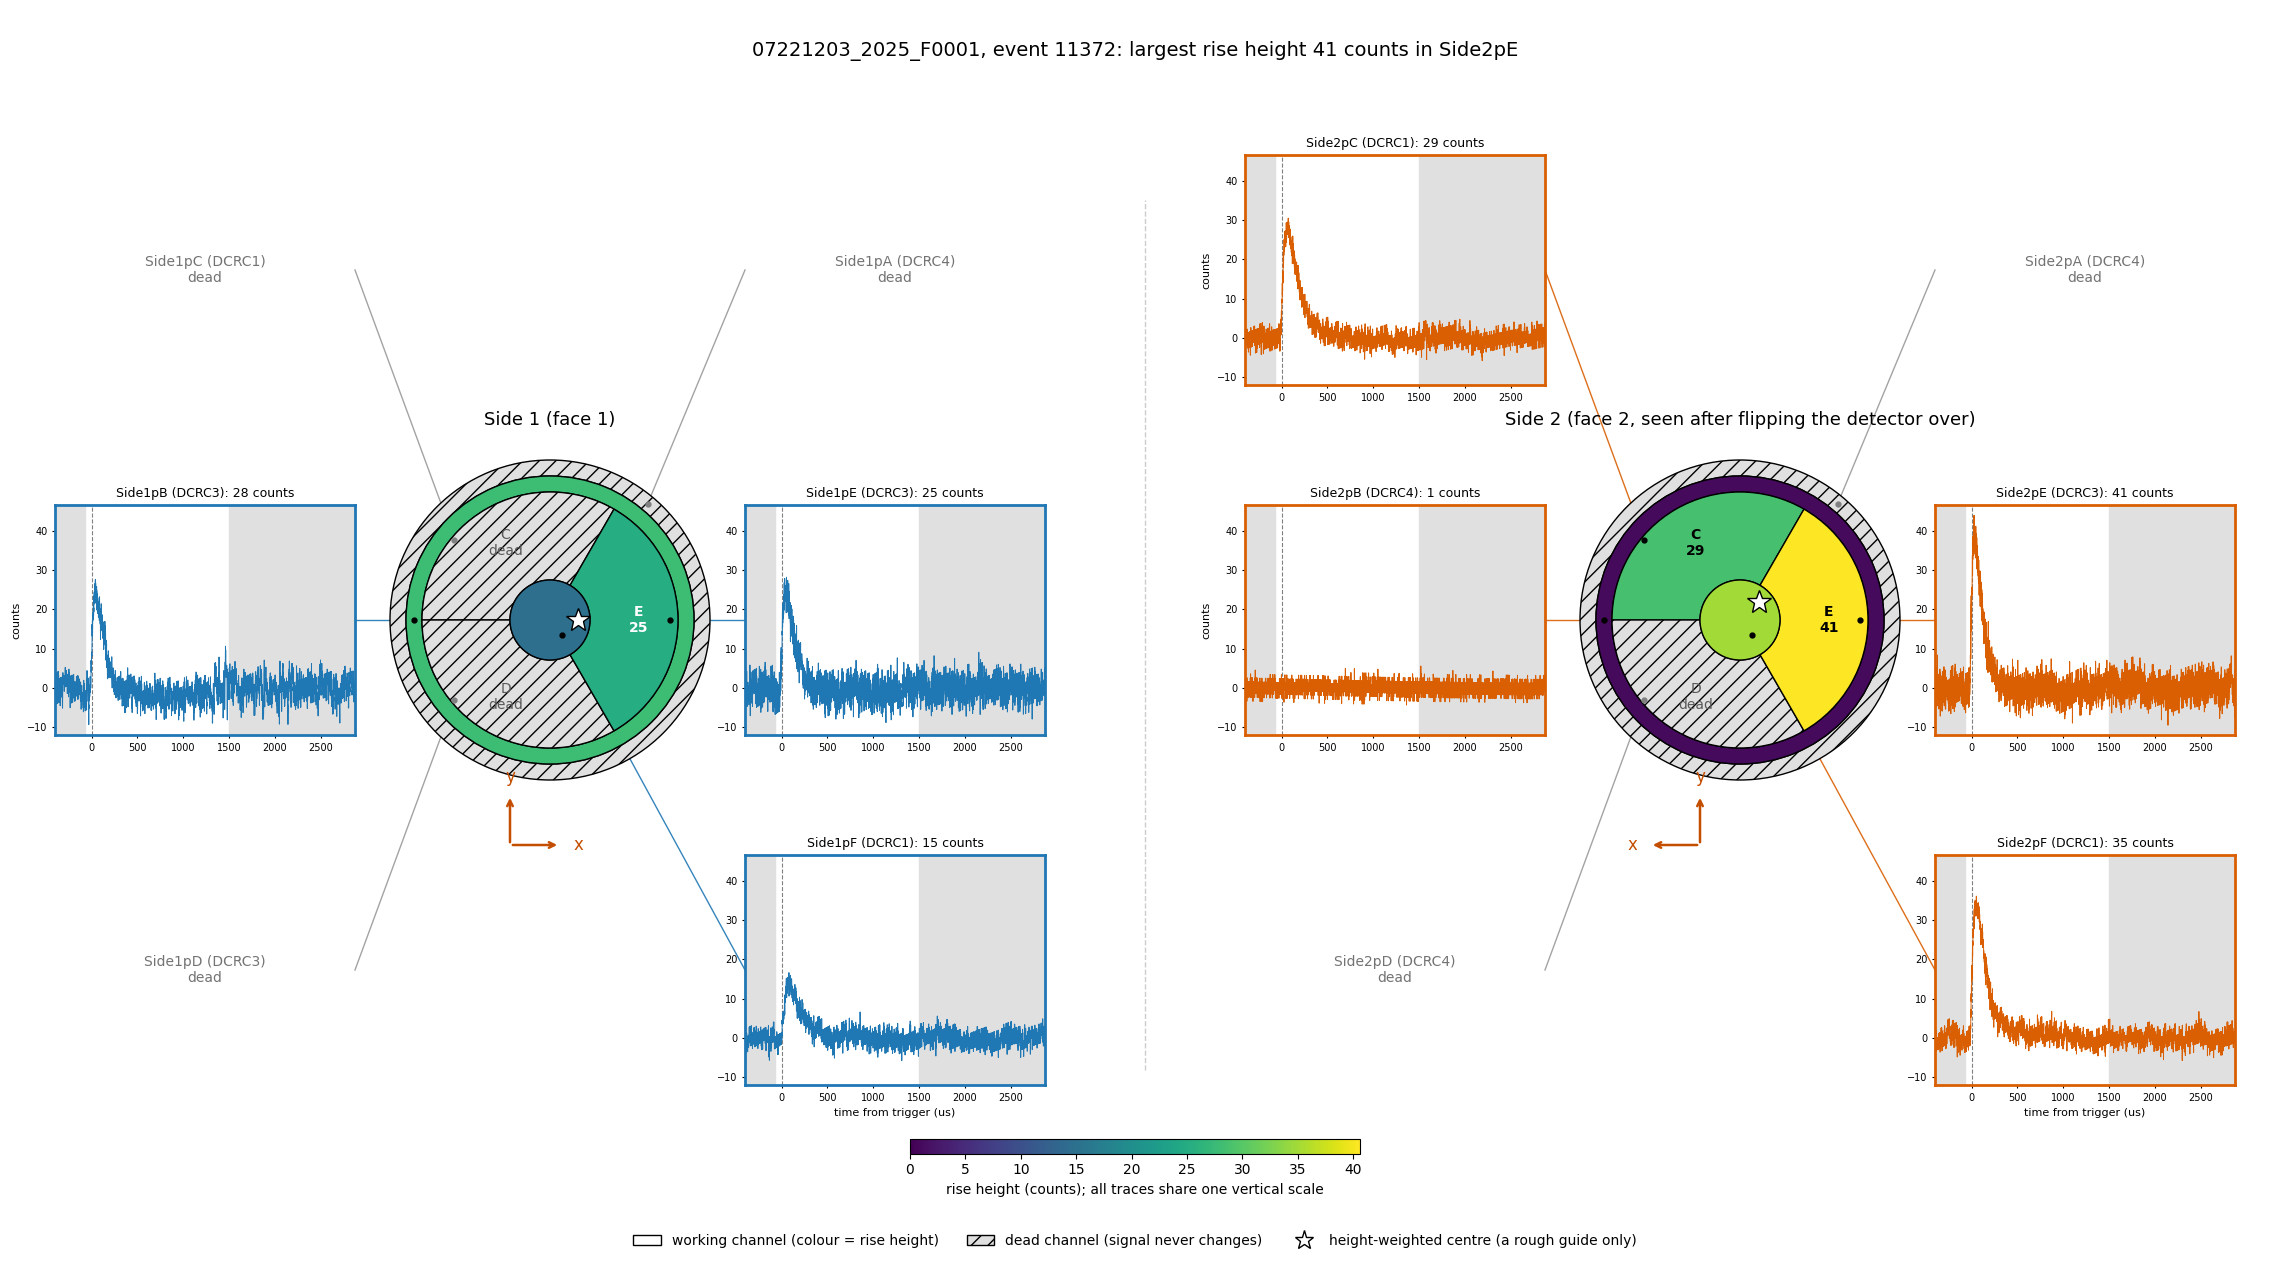

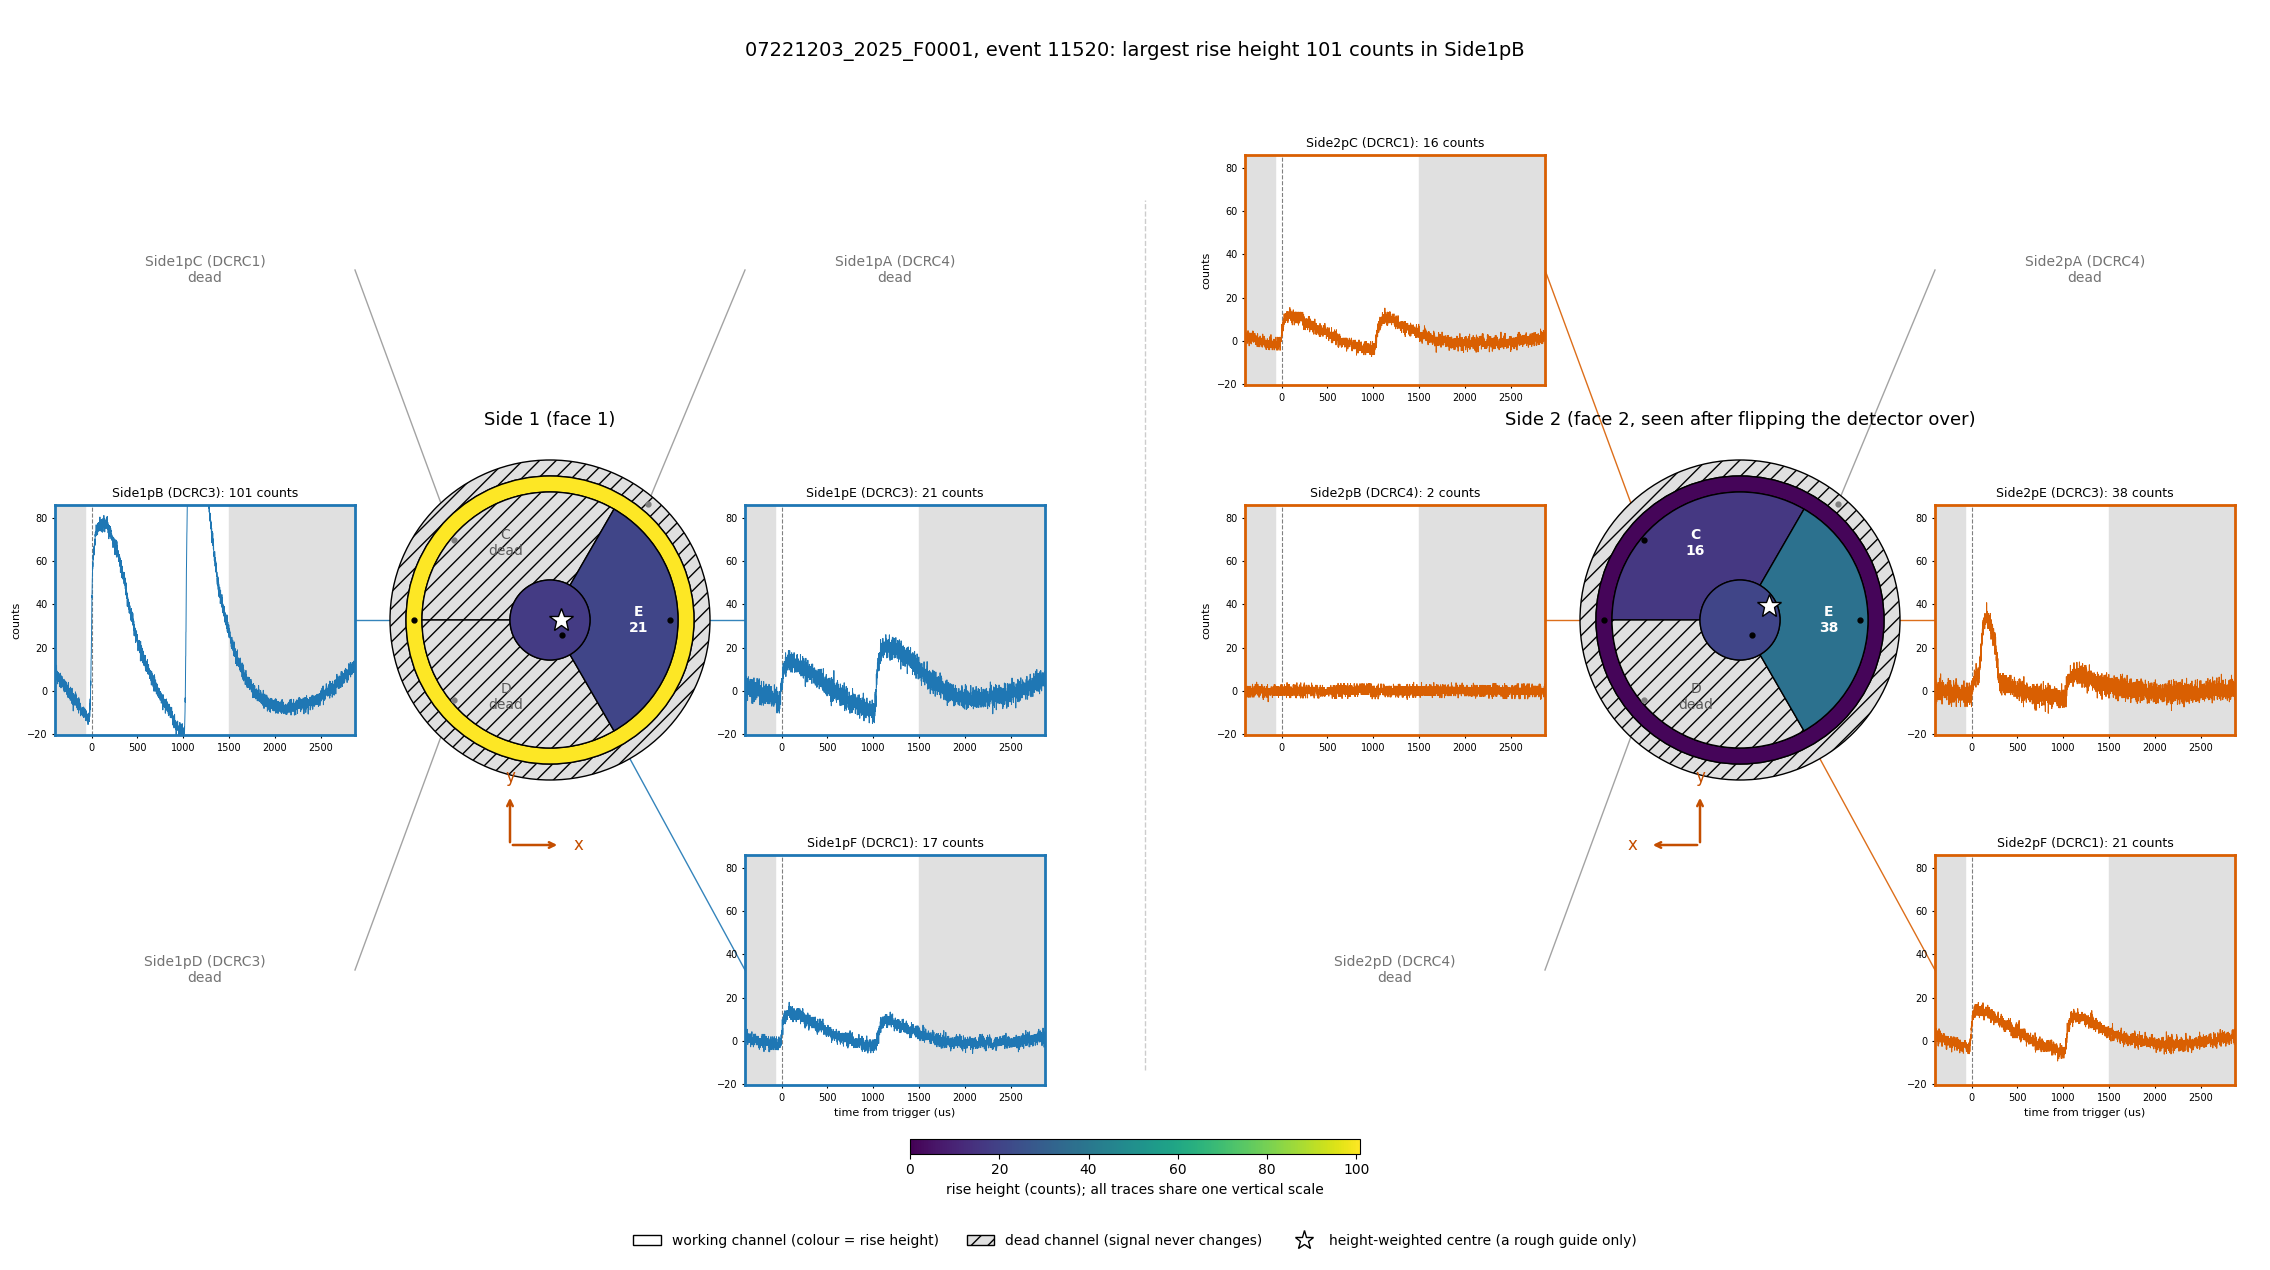

In [3]:
N_EVENTS = 3
EVENTS = None                      # or a list of event numbers, e.g. [11095, 11221]
chosen = spread(N_EVENTS) if EVENTS is None else np.array([np.flatnonzero(event_numbers == ev)[0] for ev in EVENTS])

chosen_traces = {}
for key in working:
    _, p = pio.load_channel_batch(cdms, det_ids[key[0]], key[1])
    chosen_traces[key] = p[chosen]
n_samples = chosen_traces[working[0]].shape[-1]
t_us = (np.arange(n_samples) - config_500.pretrigger_samples) * config_500.sample_period_s * 1e6
t_fit = [((config_500.glitch_samples - config_500.pretrigger_samples) * config_500.sample_period_s * 1e6,
          (st.fit_end(config_500) - config_500.pretrigger_samples) * config_500.sample_period_s * 1e6),
         (st.TAIL_FROM_US, t_us[-1])]          # where the baseline is fitted: before the pulse and in the late tail
near_pulse = (t_us >= -200) & (t_us <= 750)

for n, i in enumerate(chosen):
    flats = {side_letter(k): st.subtract_baseline(chosen_traces[k][n][None, :], config_500)[0] for k in working}
    lo = min(f[near_pulse].min() for f in flats.values())
    hi = max(f[near_pulse].max() for f in flats.values())
    pad = 0.05 * (hi - lo)
    h = heights_of(i)
    fig = dl.draw_event_layout(f"{DUMP}, event {event_numbers[i]}", t_us, flats, h, t_fit, (lo - pad, hi + pad),
                               subtitle=f": largest rise height {amp_max[i]:.0f} counts in {pch.channel_name(*max_channel[i])}")
    fig.savefig(FIGDIR / f"layout-event{event_numbers[i]}-{DUMP}.png", dpi=110)
    plt.show()

## 3. Contact sheet of many events

Small maps of selected events, spread evenly in height through the selection (smallest first). Each map is coloured on its own scale, from zero to the largest height of that event, which is printed with its channel; the heights of the three large regions are printed in them. The white star is the height-weighted centre.

C:\Users\villanoa\AppData\Local\Temp\ipykernel_24348\1976294917.py:21: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  side_letter = lambda key: (pch.channel_info(*key).side, pch.channel_info(*key).letter)
C:\Users\villanoa\AppData\Local\Temp\ipykernel_24348\1579460047.py:4: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  top=f"largest {amp_max[i]:.0f} counts, in {pch.channel_name(*max_channel[i])}") for i in sheet]


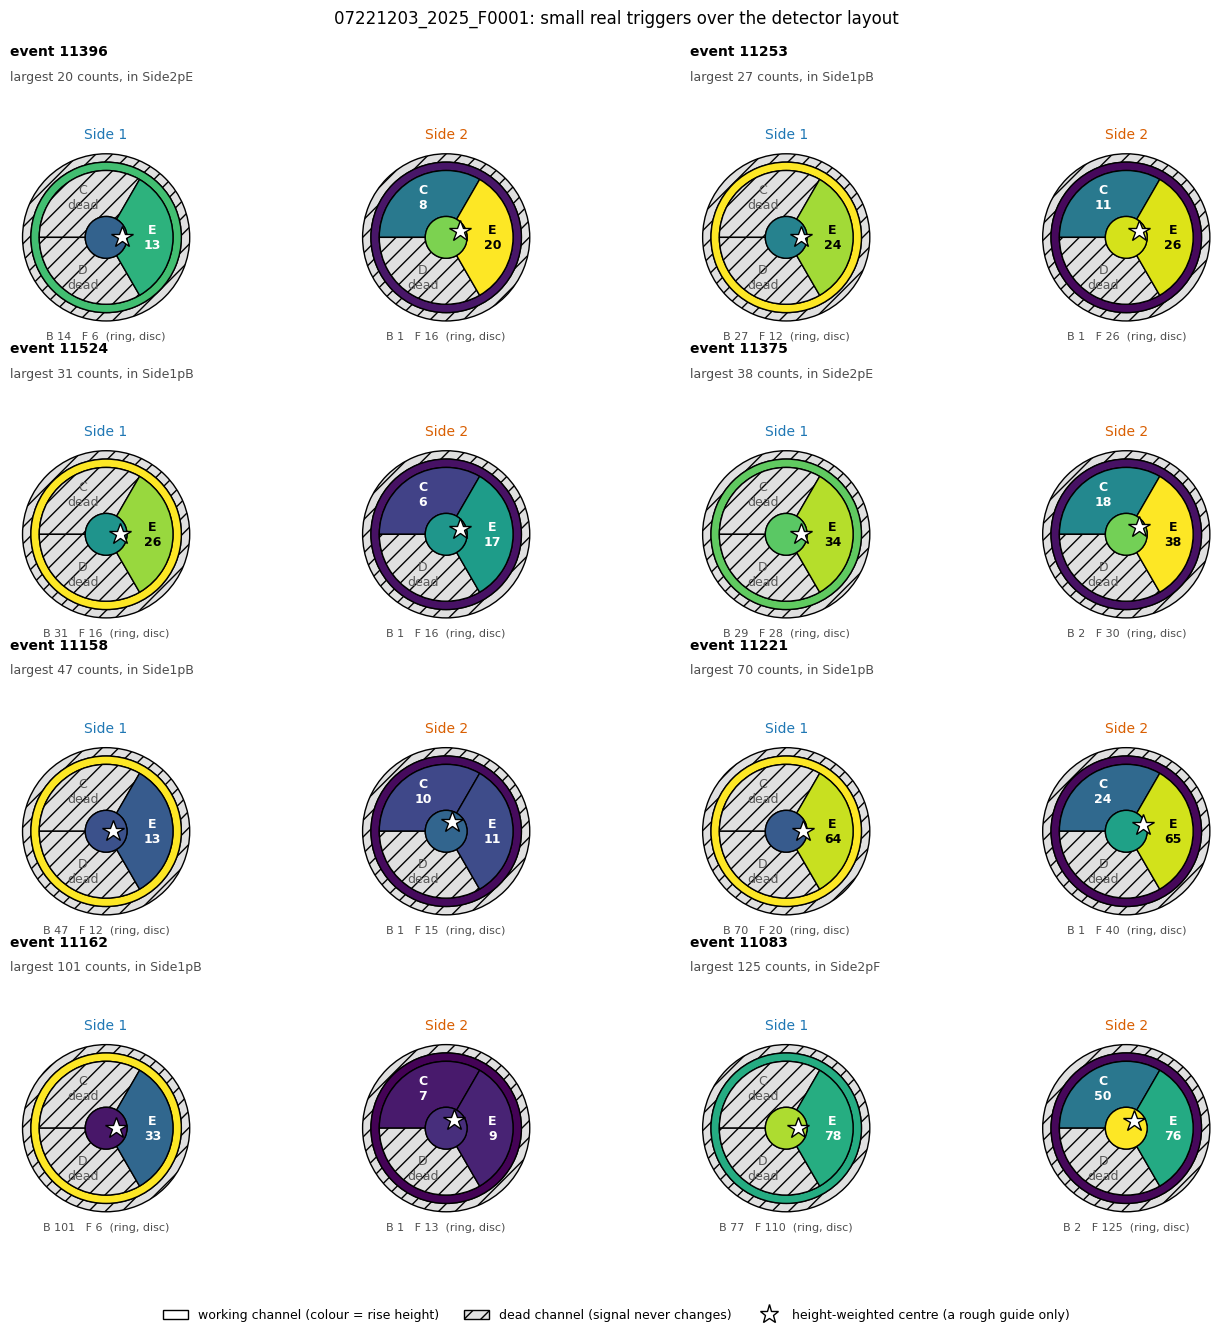

In [4]:
N_SHEET = 8
sheet = spread(N_SHEET)
events = [dict(label=f"event {event_numbers[i]}", heights=heights_of(i),
               top=f"largest {amp_max[i]:.0f} counts, in {pch.channel_name(*max_channel[i])}") for i in sheet]
fig = dl.draw_contact_sheet(events, title=f"{DUMP}: small real triggers over the detector layout")
fig.savefig(FIGDIR / f"layout-contact-sheet-{DUMP}.png", dpi=110, bbox_inches="tight")
plt.show()